# Gaze geometry features for ASD vs TD: 3 models, ranking, ensemble, SHAP, ablation

Run all cells top to bottom (Runtime > Run all). Upload `Eye-Tracking_Dataset.zip` when asked. Nothing else is needed.

Dataset note: this is an ASD vs TD dataset (Cilia et al., 2022), not ADHD. Labels come from `Metadata_Participants.csv`.

Pipeline: raw gaze CSVs, then one scanpath per participant and trial, then geometric and temporal features, then group-wise cross-validation by child (no child in both train and test), then participant-level scores.

Everything is written to `outputs/` and zipped at the end for download.

In [ ]:
# Cell 1. Setup
import subprocess, sys, importlib
def _need(pkg, mod=None):
    try: importlib.import_module(mod or pkg)
    except ImportError: subprocess.run([sys.executable,'-m','pip','-q','install',pkg],check=False)
for p,m in [('shap',None),('xgboost',None),('scikit-learn','sklearn'),('seaborn',None),('tqdm',None)]: _need(p,m)

import os, re, io, json, time, zipfile, platform, warnings, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; matplotlib.use('Agg') if os.environ.get('NB_HEADLESS') else None
import matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm
warnings.filterwarnings('ignore')

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, roc_curve, precision_recall_curve, average_precision_score,
    mean_squared_error, mean_absolute_error)
from scipy.stats import mannwhitneyu
try:
    from xgboost import XGBClassifier; HAS_XGB=True
except Exception: HAS_XGB=False

SEED=42; random.seed(SEED); np.random.seed(SEED)
OUT=Path('outputs'); (OUT/'plots').mkdir(parents=True,exist_ok=True)
T0=time.time(); TIMES={}
def tick(name,t): TIMES[name]=round(time.time()-t,2); print(f'[time] {name}: {TIMES[name]} s')
plt.rcParams.update({'figure.dpi':110,'savefig.bbox':'tight','axes.grid':True,'grid.alpha':.25})
def save(fig,name): fig.savefig(OUT/'plots'/f'{name}.png',dpi=150); plt.show()

# ---- configuration ----
SCREEN_W, SCREEN_H = 1280.0, 1024.0   # gaze coordinates are divided by these (x/W, y/H)
MIN_VALID_SAMPLES, MIN_FIXATIONS = 25, 5
N_SPLITS, N_REPEATS = 5, 3            # repeated group k-fold over children
N_PERM = 30                           # label-shuffle runs
SHARP_DEG = 90                        # a turn above this angle is 'sharp'
print('xgboost available:',HAS_XGB,'| CPUs:',os.cpu_count())

xgboost available: True | CPUs: 2


In [ ]:
# Cell 2. Locate and read the dataset zip (reads CSVs straight from the zip, no extraction)
def find_zip():
    for d in ['/content','/content/drive/MyDrive','/mnt/user-data/uploads','.']:
        for p in Path(d).glob('*.zip'):
            try:
                with zipfile.ZipFile(p) as z:
                    if any(n.endswith('Metadata_Participants.csv') for n in z.namelist()) and any('Eye-tracking Output' in n for n in z.namelist()):
                        return p
            except Exception: pass
    return None
ZIP=find_zip()
if ZIP is None:
    from google.colab import files
    print('Upload Eye-Tracking_Dataset.zip'); files.upload(); ZIP=find_zip()
assert ZIP is not None, 'Eye-Tracking dataset zip not found'
print('Using',ZIP)

zf=zipfile.ZipFile(ZIP)
csv_names=sorted([n for n in zf.namelist() if 'Eye-tracking Output' in n and n.endswith('.csv')],
                 key=lambda s:int(re.findall(r'(\d+)\.csv',s)[0]))
meta_name=[n for n in zf.namelist() if n.endswith('Metadata_Participants.csv')][0]
meta=pd.read_csv(zf.open(meta_name)); meta['pid']=meta['ParticipantID'].astype(int)
meta['label']=meta['Class'].map({'TD':0,'ASD':1}); assert meta['label'].notna().all()
print(len(csv_names),'gaze files |',len(meta),'participants |',meta['Class'].value_counts().to_dict())

Upload Eye-Tracking_Dataset.zip


Saving Eye-Tracking Dataset.zip to Eye-Tracking Dataset.zip
Using /content/Eye-Tracking Dataset.zip
25 gaze files | 59 participants | {'TD': 30, 'ASD': 29}


In [ ]:
# Cell 3. Feature extraction helpers
EPS=1e-9
def entropy_norm(vals,bins,rng):
    if len(vals)<2: return np.nan
    h,_=np.histogram(vals,bins=bins,range=rng); p=h/h.sum(); p=p[p>0]
    return float(-(p*np.log(p)).sum()/np.log(bins))

def trial_features(t,x,y,cat,idx):
    # t ms, x,y normalised, cat event label, idx event index. Arrays sorted by time, all same length.
    f={}; n=len(t); dur_s=(t[-1]-t[0])/1000.0 if n>1 else np.nan
    ok=np.isfinite(x)&np.isfinite(y)&(x>0)&(y>0)&(x<=1.2)&(y<=1.2)
    f['valid_ratio']=ok.mean(); f['blink_frac']=(cat=='Blink').mean(); f['trial_dur_s']=dur_s
    if ok.sum()<MIN_VALID_SAMPLES or not np.isfinite(dur_s) or dur_s<=0: return None
    # raw-sample dynamics (skip gaps)
    tt,xx,yy=t[ok],x[ok],y[ok]; dt=np.diff(tt)/1000.0; good=(dt>0.005)&(dt<0.1)
    d=np.hypot(np.diff(xx),np.diff(yy))
    sp=(d[good]/dt[good]) if good.any() else np.array([])
    f['vel_mean']=sp.mean() if len(sp) else np.nan; f['vel_sd']=sp.std() if len(sp) else np.nan
    f['vel_peak']=np.percentile(sp,99) if len(sp) else np.nan
    if len(sp)>2:
        ac=np.abs(np.diff(sp))/dt[good][1:]; f['acc_mean']=ac.mean(); f['acc_peak']=np.percentile(ac,95)
    else: f['acc_mean']=f['acc_peak']=np.nan
    # events by run-length of (category, index)
    key=pd.Series(cat).astype(str)+'_'+pd.Series(idx).astype(str)
    run=(key!=key.shift()).cumsum().values
    fx,fy,fd,nsac=[],[],[],0
    for r in np.unique(run):
        m=run==r; c=cat[m][0]
        if c=='Fixation':
            mm=m&ok
            if mm.sum()>=1:
                fx.append(x[mm].mean()); fy.append(y[mm].mean()); fd.append((t[m][-1]-t[m][0])+20.0)
        elif c=='Saccade': nsac+=1
    fx,fy,fd=np.array(fx),np.array(fy),np.array(fd)
    nf=len(fx)
    if nf<MIN_FIXATIONS: return None
    f['n_fix']=nf; f['fix_rate']=nf/dur_s
    f['fix_dur_mean']=fd.mean(); f['fix_dur_sd']=fd.std(); f['fix_dur_median']=np.median(fd)
    f['n_sacc']=nsac; f['sacc_rate']=nsac/dur_s
    vx,vy=np.diff(fx),np.diff(fy); L=np.hypot(vx,vy); keep=L>1e-6; vx,vy,L=vx[keep],vy[keep],L[keep]
    if len(L)<3: return None
    f['sacc_amp_mean']=L.mean(); f['sacc_amp_sd']=L.std(); f['sacc_amp_max']=L.max()
    ang=np.arctan2(vy,vx)
    f['horiz_frac']=float((np.abs(np.cos(ang))>np.cos(np.pi/4)).mean())
    f['dir_resultant']=float(np.hypot(np.cos(ang).mean(),np.sin(ang).mean()))
    f['dir_entropy']=entropy_norm(ang,12,(-np.pi,np.pi))
    dot=vx[:-1]*vx[1:]+vy[:-1]*vy[1:]; cr=vx[:-1]*vy[1:]-vy[:-1]*vx[1:]
    turn=np.degrees(np.arccos(np.clip(dot/(L[:-1]*L[1:]+EPS),-1,1)))
    f['turn_mean']=turn.mean(); f['turn_median']=np.median(turn); f['turn_sd']=turn.std()
    f['turn_p90']=np.percentile(turn,90); f['turn_p95']=np.percentile(turn,95)
    f['sharp_turn_frac']=float((turn>SHARP_DEG).mean()); f['ang_entropy']=entropy_norm(turn,12,(0,180))
    s=np.sign(cr); s=s[s!=0]
    f['dir_change_rate']=float((np.diff(s)!=0).sum()/dur_s) if len(s)>1 else 0.0
    pl=L.sum(); f['path_len_norm']=pl; f['path_len_rate']=pl/dur_s
    f['straightness']=float(np.hypot(fx[-1]-fx[0],fy[-1]-fy[0])/(pl+EPS))
    f['dispersion']=float(np.sqrt(fx.var()+fy.var()))
    f['bbox_area']=float((fx.max()-fx.min())*(fy.max()-fy.min()))
    return f

GROUPS={
 'geometry':['path_len_norm','path_len_rate','straightness','dispersion','bbox_area','dir_entropy','dir_resultant'],
 'turning':['turn_mean','turn_median','turn_sd','turn_p90','turn_p95','sharp_turn_frac','ang_entropy','dir_change_rate'],
 'dynamics':['vel_mean','vel_sd','vel_peak','acc_mean','acc_peak'],
 'fixation':['n_fix','fix_rate','fix_dur_mean','fix_dur_sd','fix_dur_median'],
 'saccade':['n_sacc','sacc_rate','sacc_amp_mean','sacc_amp_sd','sacc_amp_max','horiz_frac'],
}
QUALITY=['valid_ratio','blink_frac','trial_dur_s']   # kept out of the models; used only as a confound check
FEATS=[c for g in GROUPS.values() for c in g]
FEAT2GROUP={c:g for g,cs in GROUPS.items() for c in cs}
print(len(FEATS),'model features in',len(GROUPS),'groups')

31 model features in 5 groups


In [ ]:
# Cell 4. Build the trial table from every gaze file
t=time.time()
USE=['RecordingTime [ms]','Trial','Stimulus','Participant','Category Group','Category Right','Index Right',
     'Point of Regard Right X [px]','Point of Regard Right Y [px]']
rows=[]; skipped=0; total=0; fcount={}
for name in tqdm(csv_names,desc='files'):
    d=pd.read_csv(zf.open(name),usecols=USE,na_values=['-'],low_memory=False,encoding='latin-1')
    d=d[d['Category Group']=='Eye']
    d['Participant']=pd.to_numeric(d['Participant'],errors='coerce')
    d=d.dropna(subset=['Participant']); d['Participant']=d['Participant'].astype(int)
    d=d[d['Participant'].isin(meta['pid'])]
    for c in ['RecordingTime [ms]','Point of Regard Right X [px]','Point of Regard Right Y [px]']:
        d[c]=pd.to_numeric(d[c],errors='coerce')
    for (pid,trial,stim),g in d.groupby(['Participant','Trial','Stimulus'],sort=False):
        total+=1
        g=g.sort_values('RecordingTime [ms]')
        f=trial_features(g['RecordingTime [ms]'].values,g['Point of Regard Right X [px]'].values/SCREEN_W,
                         g['Point of Regard Right Y [px]'].values/SCREEN_H,g['Category Right'].astype(str).values,
                         g['Index Right'].values)
        if f is None: skipped+=1; continue
        f.update(pid=pid,trial=trial,stimulus=stim,file=name.split('/')[-1]); rows.append(f)
trials=pd.DataFrame(rows).merge(meta[['pid','label','Class','Gender','Age']],on='pid')
trials['stim_type']=np.where(trials['stimulus'].str.lower().str.endswith('.avi'),'video','image')
trials=trials.replace([np.inf,-np.inf],np.nan)
dup=trials.duplicated(['pid','trial','stimulus']).sum()
if dup: print('dropping',dup,'duplicate (child, trial, stimulus) rows'); trials=trials.drop_duplicates(['pid','trial','stimulus'])
print('trials kept:',len(trials),'of',total,'| skipped (too short/invalid):',skipped)
print('participants with trials:',trials['pid'].nunique(),'|',trials.groupby('Class')['pid'].nunique().to_dict())
print('trials per class:',trials['Class'].value_counts().to_dict())
trials.to_csv(OUT/'trial_features.csv',index=False); tick('feature_extraction',t)

files:   0%|          | 0/25 [00:00<?, ?it/s]

dropping 61 duplicate (child, trial, stimulus) rows
trials kept: 2044 of 3227 | skipped (too short/invalid): 1122
participants with trials: 57 | {'ASD': 27, 'TD': 30}
trials per class: {'TD': 1352, 'ASD': 692}
[time] feature_extraction: 27.26 s


stimuli total: 148 | seen by both groups: 124
trials on shared stimuli: 1982 of 2044
fraction of each group's trials on shared stimuli: {'ASD': 0.954, 'TD': 0.978}
SHARED_ONLY = False
children used: {'ASD': 27, 'TD': 30} | trials used: 2044


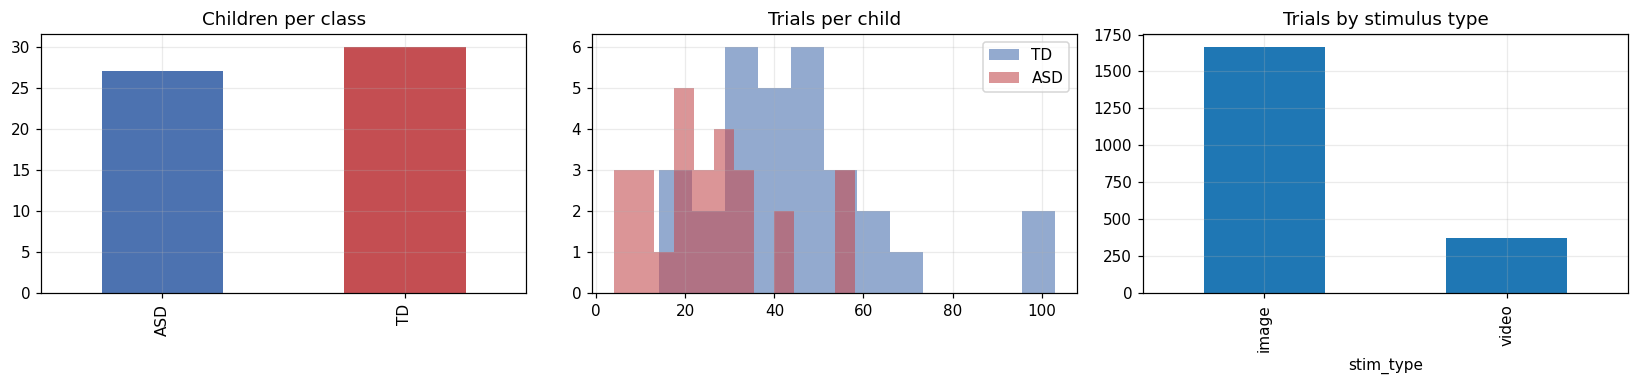

In [ ]:
# Cell 5. Data checks: do the groups see the same stimuli?
sp=trials.groupby(['stimulus','Class'])['pid'].nunique().unstack(fill_value=0)
shared=sp[(sp.get('ASD',0)>0)&(sp.get('TD',0)>0)].index
print('stimuli total:',len(sp),'| seen by both groups:',len(shared))
print('trials on shared stimuli:',trials['stimulus'].isin(shared).sum(),'of',len(trials))
share_by_cls=trials.assign(shared=trials['stimulus'].isin(shared)).groupby('Class')['shared'].mean().round(3).to_dict()
print('fraction of each group\'s trials on shared stimuli:',share_by_cls)
# Set SHARED_ONLY=True to train only on stimuli both groups viewed (removes the stimulus-set confound).
SHARED_ONLY = (len(shared)>=5) and (trials['stimulus'].isin(shared).sum()>=0.3*len(trials)) and min(share_by_cls.values())<0.95
print('SHARED_ONLY =',SHARED_ONLY)
data=trials[trials['stimulus'].isin(shared)].copy() if SHARED_ONLY else trials.copy()
# need both classes with enough children
cc=data.groupby('Class')['pid'].nunique(); print('children used:',cc.to_dict(),'| trials used:',len(data))
assert cc.min()>=8, 'too few children in one class'
fig,ax=plt.subplots(1,3,figsize=(15,3.6))
data.groupby('Class')['pid'].nunique().plot.bar(ax=ax[0],color=['#4c72b0','#c44e52'],title='Children per class'); ax[0].set_xlabel('')
data.groupby('pid').size().groupby(data.groupby('pid')['label'].first()).apply(list)
for c,col in [('TD','#4c72b0'),('ASD','#c44e52')]:
    ax[1].hist(data[data.Class==c].groupby('pid').size(),bins=12,alpha=.6,label=c,color=col)
ax[1].set_title('Trials per child'); ax[1].legend()
data['stim_type'].value_counts().plot.bar(ax=ax[2],title='Trials by stimulus type'); plt.tight_layout(); save(fig,'01_data_overview')

           feature     group  ASD_median  TD_median  cliffs_delta  ci_low  ci_high       p    p_BH    size
0     fix_dur_mean  fixation    294.4728   366.6709       -0.6198 -0.8395  -0.3790  0.0001  0.0014   large
1       fix_dur_sd  fixation    157.0379   210.7818       -0.6099 -0.8212  -0.3469  0.0001  0.0014   large
2           vel_sd  dynamics      2.3556     2.0114        0.5704  0.3320   0.7865  0.0002  0.0016   large
3      sacc_amp_sd   saccade      0.1623     0.1440        0.5630  0.3146   0.7879  0.0003  0.0016   large
4       blink_frac   quality      0.0726     0.0265        0.5580  0.2697   0.7791  0.0003  0.0016   large
5   fix_dur_median  fixation    228.8708   278.6160       -0.5556 -0.7778  -0.3185  0.0003  0.0016   large
6         acc_mean  dynamics     52.3245    39.6874        0.5506  0.2950   0.7704  0.0004  0.0016   large
7         vel_mean  dynamics      1.2567     0.8722        0.5481  0.2614   0.7385  0.0004  0.0016   large
8      valid_ratio   quality      0.8

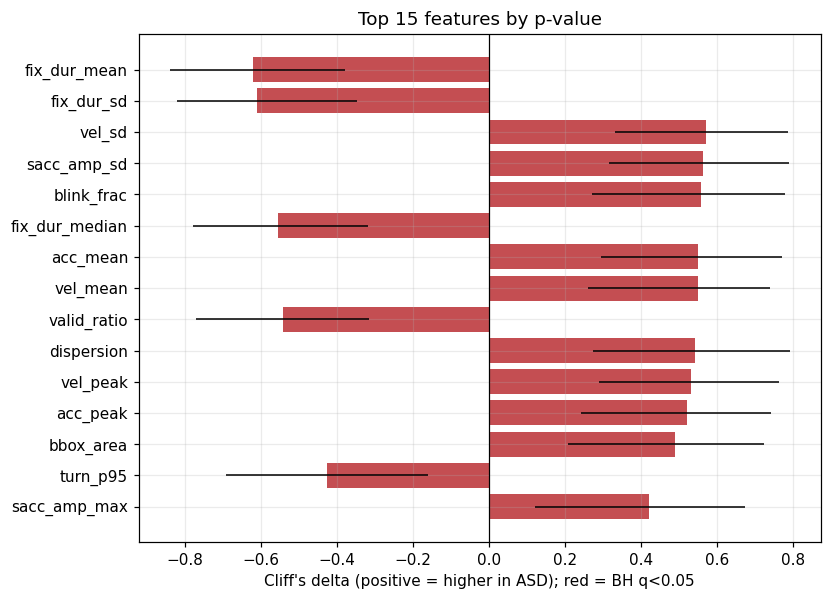

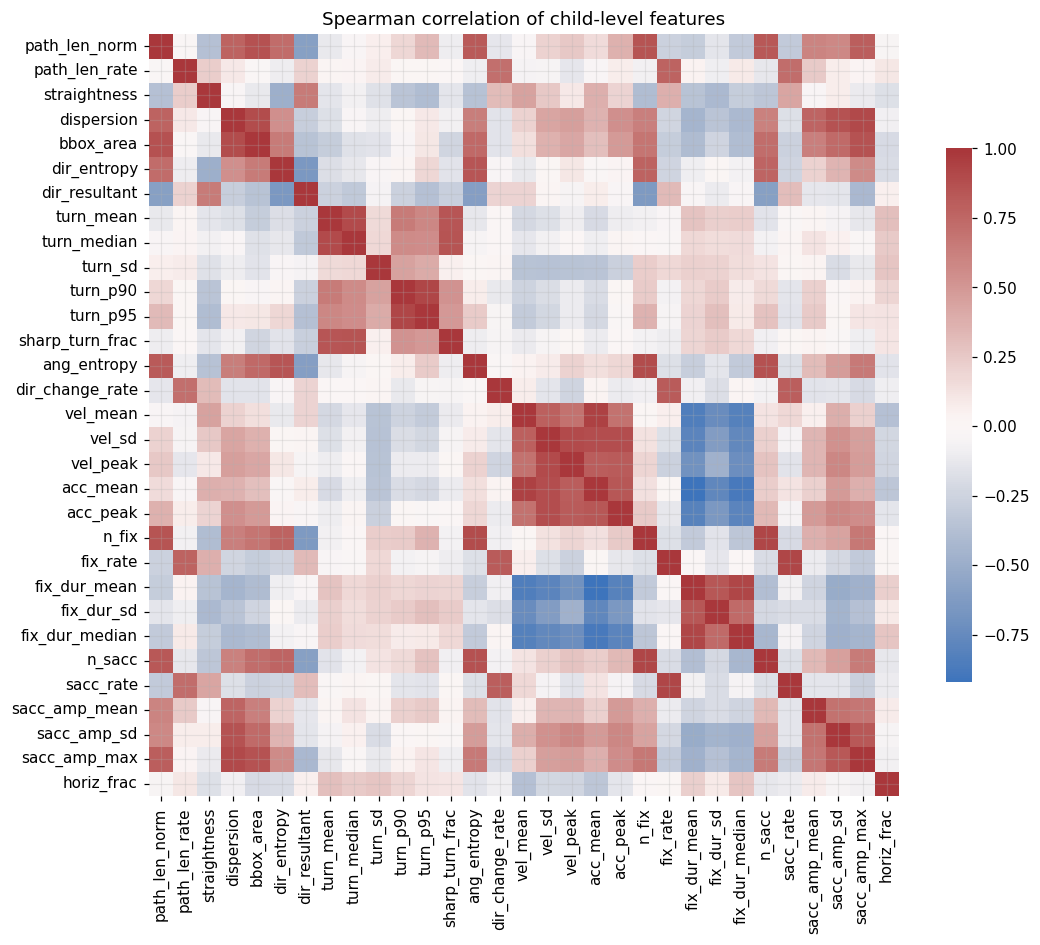

[time] statistics: 2.33 s


In [ ]:
# Cell 6. Statistical comparison at child level (median per child), Mann-Whitney, Cliff's delta, bootstrap CI, BH-FDR
t=time.time(); rng=np.random.default_rng(SEED)
pf=data.groupby('pid')[FEATS+QUALITY].median(); pf['label']=data.groupby('pid')['label'].first()
def cliff_d(a,b):
    a=np.asarray(a); b=np.asarray(b); return ((a[:,None]>b[None,:]).sum()-(a[:,None]<b[None,:]).sum())/(len(a)*len(b))
res=[]
for c in FEATS+QUALITY:
    a=pf.loc[pf.label==1,c].dropna().values; b=pf.loc[pf.label==0,c].dropna().values
    if len(a)<3 or len(b)<3: continue
    p=mannwhitneyu(a,b,alternative='two-sided').pvalue; dl=cliff_d(a,b)
    bs=[cliff_d(rng.choice(a,len(a)),rng.choice(b,len(b))) for _ in range(500)]
    res.append(dict(feature=c,group=FEAT2GROUP.get(c,'quality'),ASD_median=np.median(a),ASD_IQR=np.subtract(*np.percentile(a,[75,25])),
        TD_median=np.median(b),TD_IQR=np.subtract(*np.percentile(b,[75,25])),cliffs_delta=dl,ci_low=np.percentile(bs,2.5),ci_high=np.percentile(bs,97.5),p=p))
st=pd.DataFrame(res).sort_values('p').reset_index(drop=True)
m=len(st); st['p_BH']=np.minimum.accumulate((st['p']*m/(np.arange(m)+1))[::-1])[::-1].clip(upper=1)
st['size']=pd.cut(st.cliffs_delta.abs(),[-1,.147,.33,.474,1.01],labels=['negligible','small','medium','large'])
st.to_csv(OUT/'feature_statistics.csv',index=False)
print(st[['feature','group','ASD_median','TD_median','cliffs_delta','ci_low','ci_high','p','p_BH','size']].round(4).head(15).to_string())
top=st.head(15).iloc[::-1]
fig,ax=plt.subplots(figsize=(8,6)); col=np.where(top.p_BH<.05,'#c44e52','#8c8c8c')
ax.barh(top.feature,top.cliffs_delta,color=col); ax.errorbar(top.cliffs_delta,range(len(top)),xerr=[top.cliffs_delta-top.ci_low,top.ci_high-top.cliffs_delta],fmt='none',ecolor='k',lw=1)
ax.axvline(0,color='k',lw=.8); ax.set_xlabel("Cliff's delta (positive = higher in ASD); red = BH q<0.05"); ax.set_title('Top 15 features by p-value'); save(fig,'02_effect_sizes')
cm_=pf[FEATS].corr(method='spearman'); fig,ax=plt.subplots(figsize=(11,9)); sns.heatmap(cm_,cmap='vlag',center=0,ax=ax,cbar_kws={'shrink':.7}); ax.set_title('Spearman correlation of child-level features'); save(fig,'03_feature_correlation')
tick('statistics',t)

In [ ]:
# Cell 7. Models, weights, cross-validation engine
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.pipeline import Pipeline
XGB_NAME='XGBoost' if HAS_XGB else 'HistGradientBoosting'
def make_model(name,seed=SEED):
    imp=SimpleImputer(strategy='median')
    if name=='Logistic Regression':
        return make_pipeline(imp,QuantileTransformer(n_quantiles=200,output_distribution='normal',random_state=seed),
                             LogisticRegression(C=0.3,max_iter=3000,random_state=seed))
    if name=='Random Forest':
        return make_pipeline(imp,RandomForestClassifier(n_estimators=250,min_samples_leaf=5,max_features='sqrt',n_jobs=-1,random_state=seed))
    if HAS_XGB:
        return make_pipeline(imp,XGBClassifier(n_estimators=200,max_depth=3,learning_rate=0.05,subsample=0.8,colsample_bytree=0.8,
                             min_child_weight=3,reg_lambda=2.0,eval_metric='logloss',n_jobs=-1,random_state=seed,verbosity=0))
    return make_pipeline(imp,HistGradientBoostingClassifier(max_depth=3,learning_rate=0.05,max_iter=200,random_state=seed))
MODELS=['Logistic Regression','Random Forest',XGB_NAME]

def child_class_weights(y,pid):
    # each child counts once, each class counts half
    pid=np.asarray(pid); y=np.asarray(y); n=pd.Series(pid).map(pd.Series(pid).value_counts()).values.astype(float)
    w=1.0/n
    for c in (0,1):
        s=w[y==c].sum()
        if s>0: w[y==c]*=0.5/s
    return w*len(y)

def fit_model(model,X,y,w):
    model.fit(X,y,**{model.steps[-1][0]+'__sample_weight':w}); return model

def metrics(y,p,thr=0.5):
    y=np.asarray(y); p=np.asarray(p); pred=(p>=thr).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return dict(AUROC=roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan,AP=average_precision_score(y,p),
        Accuracy=accuracy_score(y,pred),BalancedAcc=balanced_accuracy_score(y,pred),
        Precision=precision_score(y,pred,zero_division=0),Recall=recall_score(y,pred,zero_division=0),
        Specificity=tn/(tn+fp) if (tn+fp) else np.nan,F1=f1_score(y,pred,zero_division=0),
        MSE=mean_squared_error(y,p),RMSE=float(np.sqrt(mean_squared_error(y,p))),MAE=mean_absolute_error(y,p),TP=tp,FP=fp,TN=tn,FN=fn)

def cv_run(name,cols,df,repeats=N_REPEATS,label_col='label',collect_time=True):
    # Group k-fold over children. Returns per-repeat child-level probabilities and timing.
    X=df[cols]; y=df[label_col].values; g=df['pid'].values; reps=[]; tfit=tpred=0.0; nfit=0
    for r in range(repeats):
        oof=np.full(len(df),np.nan)
        sk=StratifiedGroupKFold(n_splits=N_SPLITS,shuffle=True,random_state=SEED+r)
        for tr,te in sk.split(X,y,g):
            m=make_model(name,SEED+r); w=child_class_weights(y[tr],g[tr])
            t0=time.time(); fit_model(m,X.iloc[tr],y[tr],w); tfit+=time.time()-t0; nfit+=1
            t0=time.time(); oof[te]=m.predict_proba(X.iloc[te])[:,1]; tpred+=time.time()-t0
        d=pd.DataFrame({'pid':g,'y':y,'p':oof}); reps.append(d)
    child=[d.groupby('pid').agg(y=('y','first'),p=('p','mean')).reset_index() for d in reps]
    return dict(trial=reps,child=child,fit_s=tfit,pred_s=tpred,n_fits=nfit)

def summarize_runs(child_list):
    ms=pd.DataFrame([metrics(c['y'],c['p']) for c in child_list]); return ms
print('Models:',MODELS)

Models: ['Logistic Regression', 'Random Forest', 'XGBoost']


In [ ]:
# Cell 8. Run the three models (repeated group CV, child-level scoring), then ensemble
t=time.time(); RUNS={}; MS={}
for nm in MODELS:
    t0=time.time(); RUNS[nm]=cv_run(nm,FEATS,data); MS[nm]=summarize_runs(RUNS[nm]['child'])
    print(f"{nm:22s} child AUROC {MS[nm].AUROC.mean():.3f} +/- {MS[nm].AUROC.std():.3f} | F1 {MS[nm].F1.mean():.3f} | {time.time()-t0:.1f} s")
tick('train_3_models_cv',t)

# ranking by composite rank over several metrics
t=time.time()
summ=pd.DataFrame({nm:MS[nm].mean(numeric_only=True) for nm in MODELS}).T
rk=pd.DataFrame({'AUROC':summ.AUROC.rank(ascending=False),'F1':summ.F1.rank(ascending=False),'BalancedAcc':summ.BalancedAcc.rank(ascending=False),
                 'MSE':summ.MSE.rank(),'MAE':summ.MAE.rank()})
summ['mean_rank']=rk.mean(axis=1); order=summ.sort_values(['mean_rank','AUROC'],ascending=[True,False]).index.tolist()
rank_w=pd.Series({nm:(len(order)-i) for i,nm in enumerate(order)}); rank_w=rank_w/rank_w.sum()
print('Ranking:',order,'| rank weights:',rank_w.round(3).to_dict())

# ensembles, computed repeat by repeat from the same out-of-fold probabilities
def combine(wts):
    out=[]
    for r in range(N_REPEATS):
        base=RUNS[MODELS[0]]['child'][r][['pid','y']].copy()
        base['p']=sum(wts[nm]*RUNS[nm]['child'][r].set_index('pid').loc[base.pid,'p'].values for nm in MODELS); out.append(base)
    return out
ENS={'Ensemble (equal)':combine({nm:1/len(MODELS) for nm in MODELS}),'Ensemble (rank-weighted)':combine(rank_w.to_dict())}
for k,v in ENS.items(): MS[k]=summarize_runs(v); RUNS[k]=dict(child=v,fit_s=np.nan,pred_s=np.nan,n_fits=np.nan)
ALL=MODELS+list(ENS)
final=pd.DataFrame({nm:MS[nm].mean(numeric_only=True) for nm in ALL}).T
final_sd=pd.DataFrame({nm:MS[nm].std(numeric_only=True) for nm in ALL}).T
final['fit_time_total_s']=[RUNS[nm]['fit_s'] for nm in ALL]; final['predict_time_total_s']=[RUNS[nm]['pred_s'] for nm in ALL]
final['fit_time_per_fold_s']=final.fit_time_total_s/[RUNS[nm]['n_fits'] for nm in ALL]
final.to_csv(OUT/'model_metrics_mean.csv'); final_sd.to_csv(OUT/'model_metrics_sd.csv')
pd.concat({nm:MS[nm] for nm in ALL}).to_csv(OUT/'model_metrics_per_repeat.csv')
show=['AUROC','AP','Accuracy','BalancedAcc','Precision','Recall','Specificity','F1','MSE','MAE','fit_time_total_s']
print(final[show].round(3).sort_values('AUROC',ascending=False).to_string())
print('\nSD over repeats:'); print(final_sd[['AUROC','F1','MSE','MAE']].round(3).to_string())
pred_tbl=pd.DataFrame({'pid':RUNS[MODELS[0]]['child'][0].pid,'true':RUNS[MODELS[0]]['child'][0].y})
for nm in ALL: pred_tbl[nm]=np.mean([c.set_index('pid').loc[pred_tbl.pid,'p'].values for c in RUNS[nm]['child']],axis=0)
pred_tbl.to_csv(OUT/'child_level_predictions.csv',index=False); tick('rank_and_ensemble',t)

Logistic Regression    child AUROC 0.802 +/- 0.025 | F1 0.688 | 1.6 s
Random Forest          child AUROC 0.759 +/- 0.014 | F1 0.541 | 28.7 s
XGBoost                child AUROC 0.776 +/- 0.027 | F1 0.604 | 5.3 s
[time] train_3_models_cv: 35.59 s
Ranking: ['Logistic Regression', 'XGBoost', 'Random Forest'] | rank weights: {'Logistic Regression': 0.5, 'XGBoost': 0.333, 'Random Forest': 0.167}
                          AUROC     AP  Accuracy  BalancedAcc  Precision  Recall  Specificity     F1    MSE    MAE  fit_time_total_s
Logistic Regression       0.802  0.841     0.719        0.716      0.726   0.654        0.778  0.688  0.193  0.423             0.994
Ensemble (rank-weighted)  0.789  0.829     0.731        0.723      0.806   0.568        0.878  0.666  0.196  0.426               NaN
Ensemble (equal)          0.778  0.818     0.731        0.719      0.890   0.494        0.944  0.635  0.199  0.428               NaN
XGBoost                   0.776  0.816     0.702        0.691      0.812   

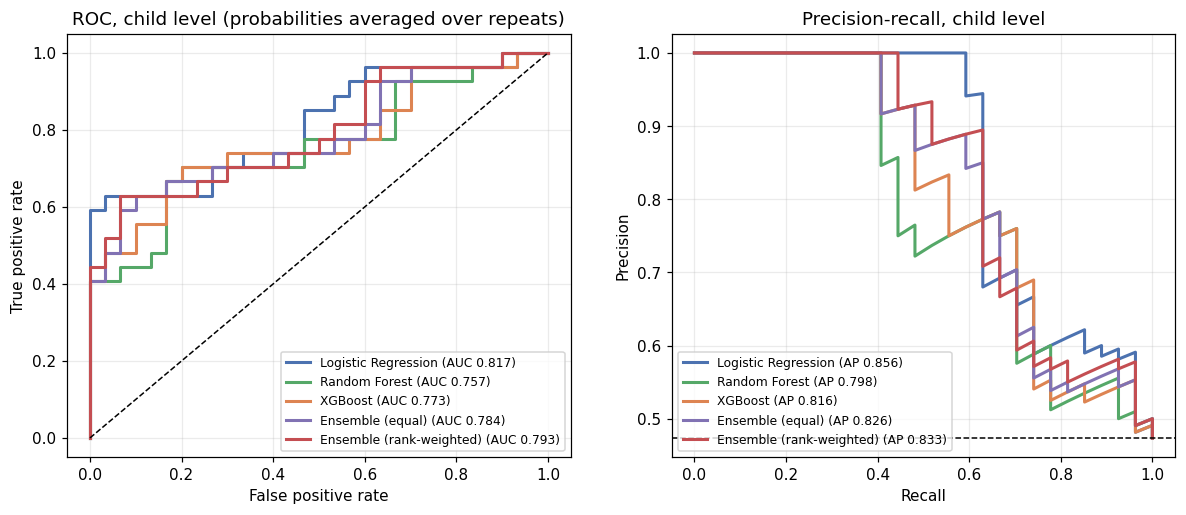

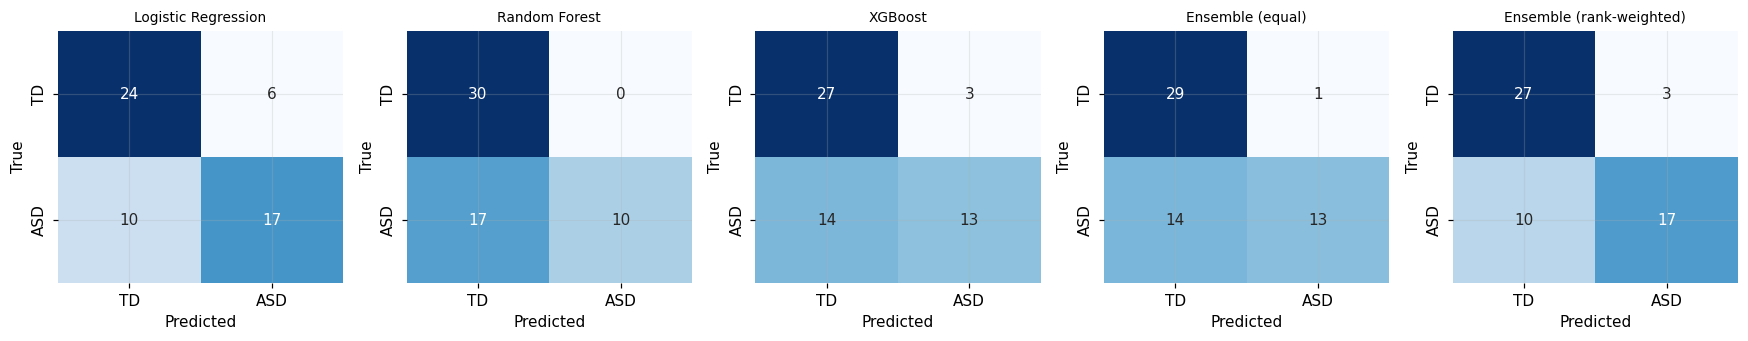

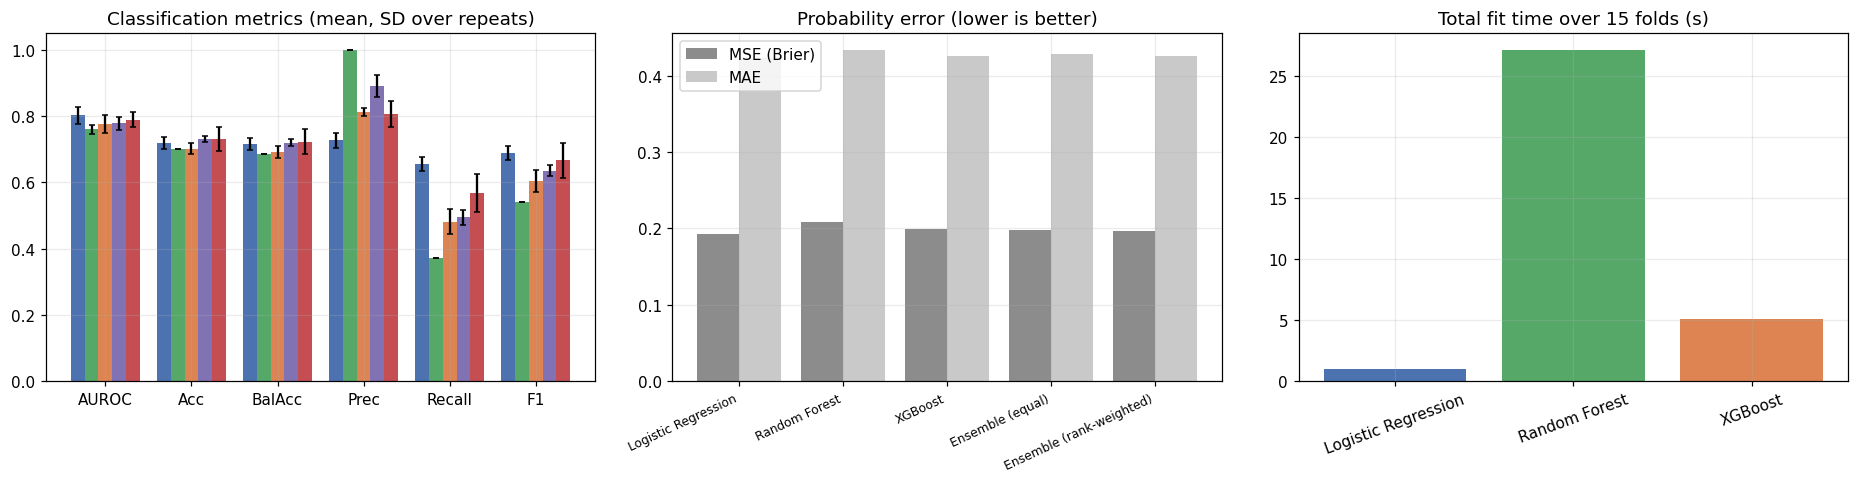

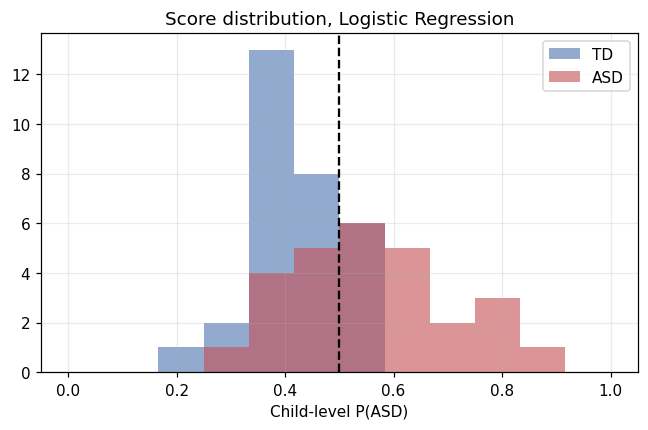

[time] plots_models: 3.72 s


In [ ]:
# Cell 9. Plots: ROC, precision-recall, confusion matrices, metric bars, errors, time
t=time.time(); cols=dict(zip(ALL,['#4c72b0','#55a868','#dd8452','#8172b3','#c44e52']))
fig,ax=plt.subplots(1,2,figsize=(13,5))
for nm in ALL:
    fpr,tpr,_=roc_curve(pred_tbl.true,pred_tbl[nm]); ax[0].plot(fpr,tpr,color=cols[nm],lw=2,label=f'{nm} (AUC {roc_auc_score(pred_tbl.true,pred_tbl[nm]):.3f})')
    pr,rc,_=precision_recall_curve(pred_tbl.true,pred_tbl[nm]); ax[1].plot(rc,pr,color=cols[nm],lw=2,label=f'{nm} (AP {average_precision_score(pred_tbl.true,pred_tbl[nm]):.3f})')
ax[0].plot([0,1],[0,1],'k--',lw=1); ax[0].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC, child level (probabilities averaged over repeats)'); ax[0].legend(loc='lower right',fontsize=8)
ax[1].axhline(pred_tbl.true.mean(),color='k',ls='--',lw=1); ax[1].set(xlabel='Recall',ylabel='Precision',title='Precision-recall, child level'); ax[1].legend(loc='lower left',fontsize=8); save(fig,'04_roc_pr')

fig,ax=plt.subplots(1,len(ALL),figsize=(3.2*len(ALL),3.2))
for a,nm in zip(ax,ALL):
    cmx=confusion_matrix(pred_tbl.true,(pred_tbl[nm]>=.5).astype(int),labels=[0,1]); sns.heatmap(cmx,annot=True,fmt='d',cmap='Blues',cbar=False,ax=a,xticklabels=['TD','ASD'],yticklabels=['TD','ASD']); a.set_title(nm,fontsize=9); a.set_xlabel('Predicted'); a.set_ylabel('True')
plt.tight_layout(); save(fig,'05_confusion_matrices')

fig,ax=plt.subplots(1,3,figsize=(17,4.5)); w=0.8/len(ALL)
for j,mt in enumerate(['AUROC','Accuracy','BalancedAcc','Precision','Recall','F1']):
    ax[0].bar(np.arange(len(ALL))*0+j+np.arange(len(ALL))*w-0.4+w/2,[final.loc[nm,mt] for nm in ALL],w,yerr=[final_sd.loc[nm,mt] for nm in ALL],color=[cols[n] for n in ALL],capsize=2)
ax[0].set_xticks(range(6)); ax[0].set_xticklabels(['AUROC','Acc','BalAcc','Prec','Recall','F1']); ax[0].set_ylim(0,1.05); ax[0].set_title('Classification metrics (mean, SD over repeats)')
x=np.arange(len(ALL)); ax[1].bar(x-.2,final.loc[ALL,'MSE'],.4,label='MSE (Brier)',color='#8c8c8c'); ax[1].bar(x+.2,final.loc[ALL,'MAE'],.4,label='MAE',color='#c9c9c9'); ax[1].set_xticks(x); ax[1].set_xticklabels(ALL,rotation=25,ha='right',fontsize=8); ax[1].legend(); ax[1].set_title('Probability error (lower is better)')
ax[2].bar(MODELS,final.loc[MODELS,'fit_time_total_s'],color=[cols[n] for n in MODELS]); ax[2].set_title(f'Total fit time over {N_SPLITS*N_REPEATS} folds (s)'); ax[2].tick_params(axis='x',rotation=20)
plt.tight_layout(); save(fig,'06_metrics_errors_time')

best_nm=order[0]; fig,ax=plt.subplots(figsize=(7,4))
for lab,c in [(0,'#4c72b0'),(1,'#c44e52')]: ax.hist(pred_tbl.loc[pred_tbl.true==lab,best_nm],bins=12,range=(0,1),alpha=.6,color=c,label=['TD','ASD'][lab])
ax.axvline(.5,color='k',ls='--'); ax.set(xlabel='Child-level P(ASD)',title=f'Score distribution, {best_nm}'); ax.legend(); save(fig,'07_score_distribution'); tick('plots_models',t)

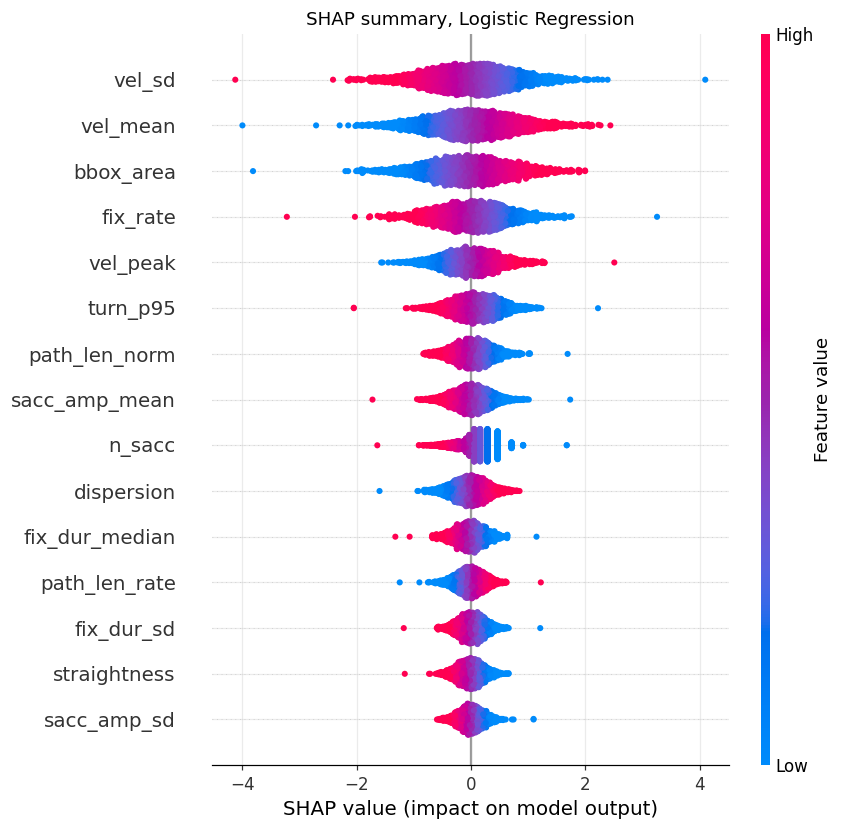

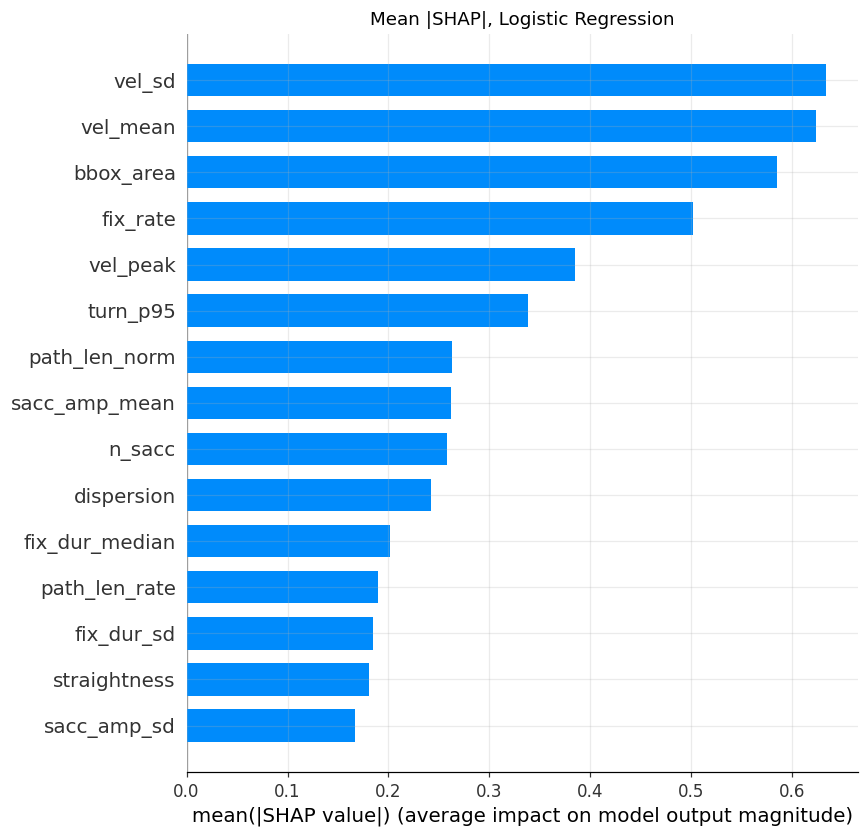

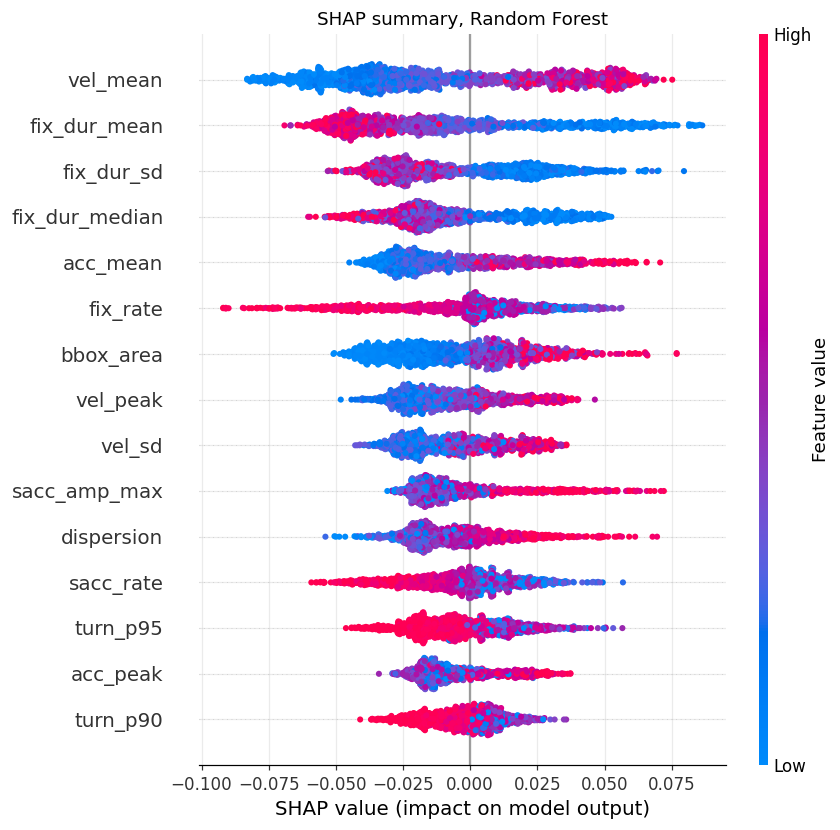

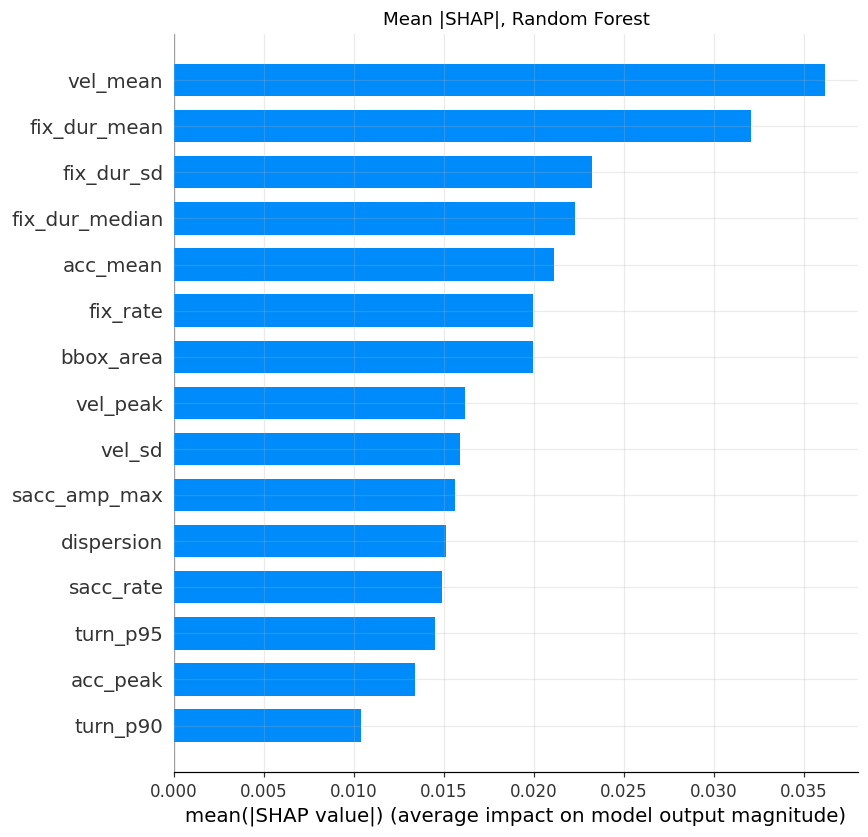

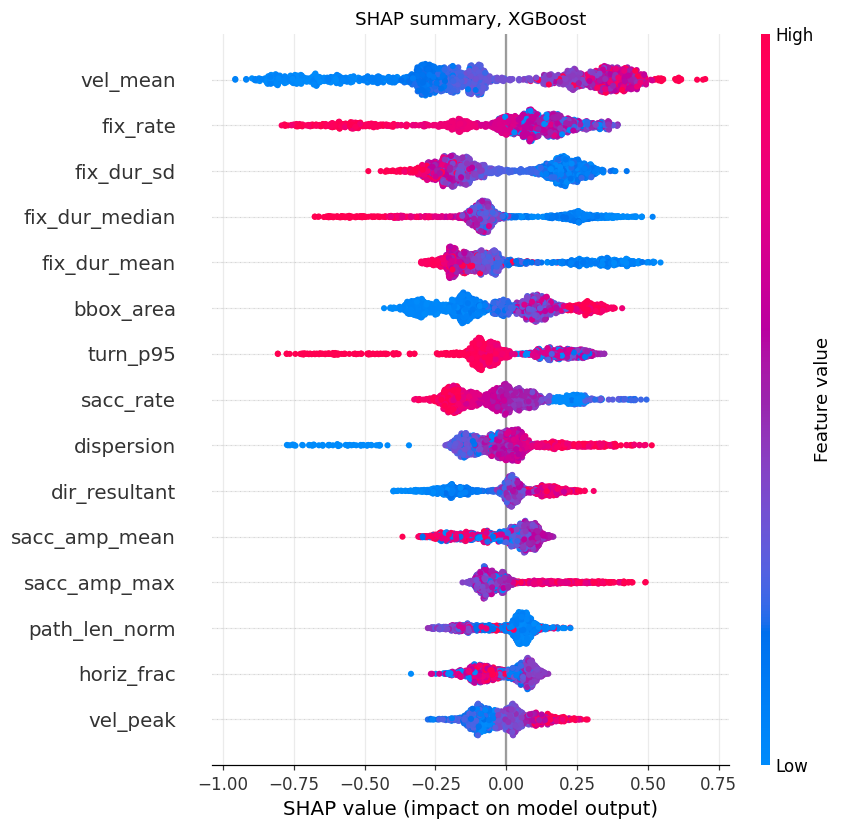

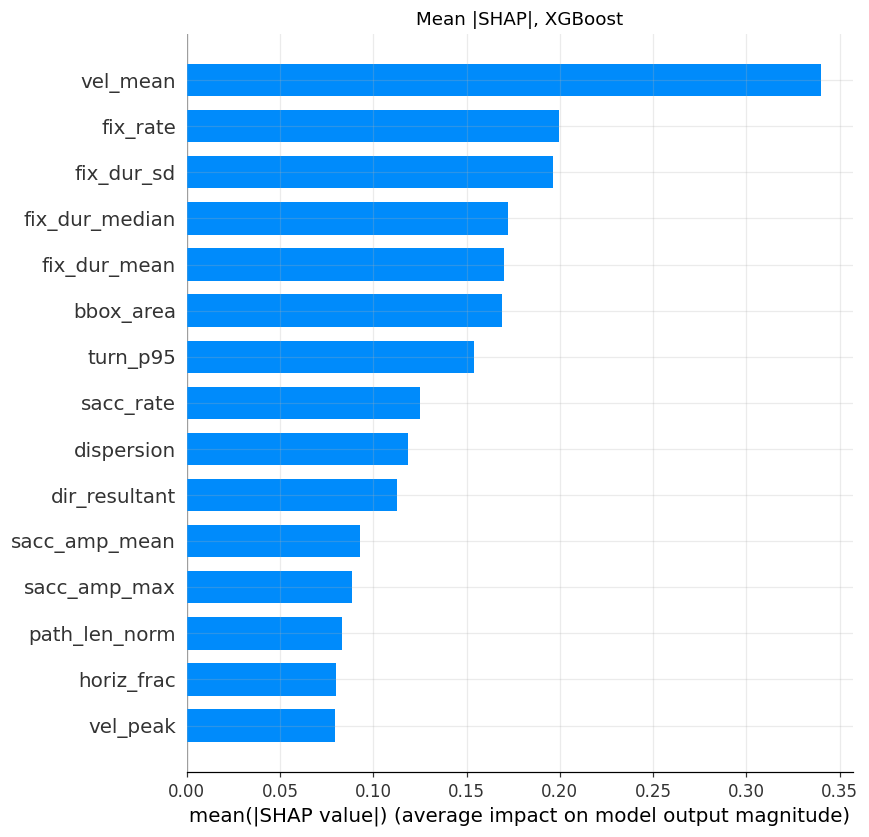

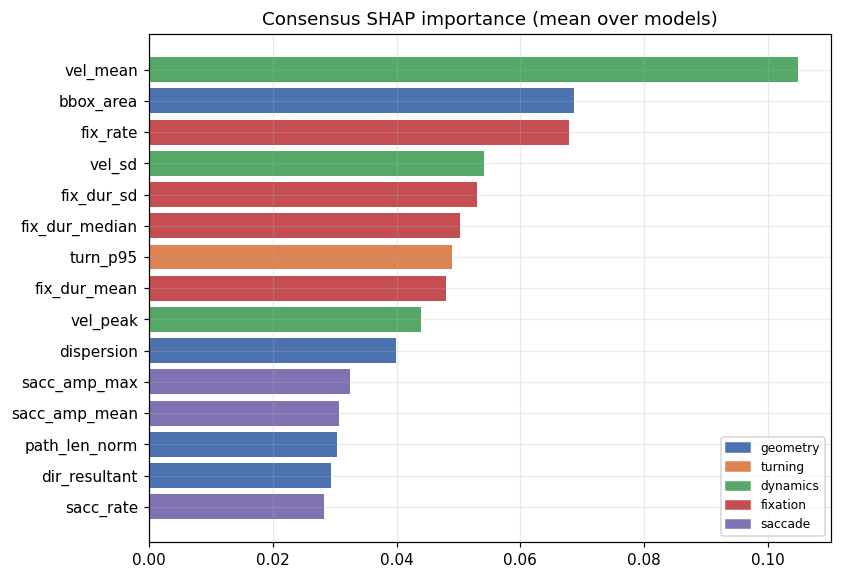

                consensus     group
vel_mean            0.105  dynamics
bbox_area           0.069  geometry
fix_rate            0.068  fixation
vel_sd              0.054  dynamics
fix_dur_sd          0.053  fixation
fix_dur_median      0.050  fixation
turn_p95            0.049   turning
fix_dur_mean        0.048  fixation
vel_peak            0.044  dynamics
dispersion          0.040  geometry
[time] shap: 37.8 s


In [ ]:
# Cell 10. SHAP for all three models (fitted on all children; explains the model, not generalisation)
import shap
t=time.time(); Xall=data[FEATS]; yall=data['label'].values; wall=child_class_weights(yall,data['pid'].values)
FINAL={nm:fit_model(make_model(nm),Xall,yall,wall) for nm in MODELS}
samp=Xall.sample(min(1500,len(Xall)),random_state=SEED); SHAPV={}
for nm in MODELS:
    try:
        pipe=FINAL[nm]; Xt=pd.DataFrame(pipe[:-1].transform(samp),columns=FEATS); est=pipe[-1]
        if nm=='Logistic Regression': sv=shap.LinearExplainer(est,Xt).shap_values(Xt)
        elif nm in ('Random Forest',XGB_NAME) and HAS_XGB or nm=='Random Forest': sv=shap.TreeExplainer(est).shap_values(Xt)
        else: sv=shap.Explainer(lambda d:est.predict_proba(d)[:,1],Xt.iloc[:100])(Xt.iloc[:300]).values; Xt=Xt.iloc[:300]
        if isinstance(sv,list): sv=sv[1]
        sv=np.asarray(sv); sv=sv[:,:,1] if sv.ndim==3 else sv
        SHAPV[nm]=(sv,Xt)
        plt.figure(); shap.summary_plot(sv,Xt,show=False,max_display=15); plt.title(f'SHAP summary, {nm}'); save(plt.gcf(),f'08_shap_beeswarm_{nm.replace(" ","_")}')
        plt.figure(); shap.summary_plot(sv,Xt,plot_type='bar',show=False,max_display=15); plt.title(f'Mean |SHAP|, {nm}'); save(plt.gcf(),f'09_shap_bar_{nm.replace(" ","_")}')
    except Exception as e: print('SHAP failed for',nm,'->',repr(e)[:200])
if SHAPV:
    imp=pd.DataFrame({nm:np.abs(v[0]).mean(0) for nm,v in SHAPV.items()},index=FEATS)
    imp_n=imp/imp.sum(); imp_n['consensus']=imp_n.mean(axis=1); imp_n['group']=[FEAT2GROUP[f] for f in FEATS]
    imp_n=imp_n.sort_values('consensus',ascending=False); imp_n.to_csv(OUT/'shap_importance.csv')
    top=imp_n.head(15).iloc[::-1]; fig,ax=plt.subplots(figsize=(8,6)); gc=dict(zip(GROUPS,sns.color_palette('deep',len(GROUPS))))
    ax.barh(top.index,top.consensus,color=[gc[g] for g in top.group]); ax.set_title('Consensus SHAP importance (mean over models)')
    ax.legend(handles=[plt.Rectangle((0,0),1,1,color=gc[g]) for g in GROUPS],labels=list(GROUPS),loc='lower right',fontsize=8); save(fig,'10_shap_consensus')
    print(imp_n[['consensus','group']].head(10).round(3).to_string())
tick('shap',t)

Ablation model: Logistic Regression
                        config  n_features  AUROC  AUROC_sd    F1  Recall  Precision   MSE   MAE  dAUROC_vs_all
                  all features          31  0.802     0.025 0.688   0.654      0.726 0.193 0.423          0.000
                minus geometry          24  0.787     0.015 0.683   0.667      0.701 0.199 0.430         -0.016
                 minus turning          23  0.810     0.023 0.693   0.654      0.736 0.193 0.423          0.008
                minus dynamics          26  0.816     0.014 0.693   0.642      0.753 0.195 0.428          0.014
                minus fixation          26  0.810     0.019 0.675   0.654      0.698 0.194 0.426          0.007
                 minus saccade          25  0.809     0.025 0.701   0.679      0.724 0.192 0.422          0.007
                 only geometry           7  0.793     0.030 0.680   0.630      0.739 0.217 0.461         -0.009
                  only turning           8  0.653     0.018 0.598   

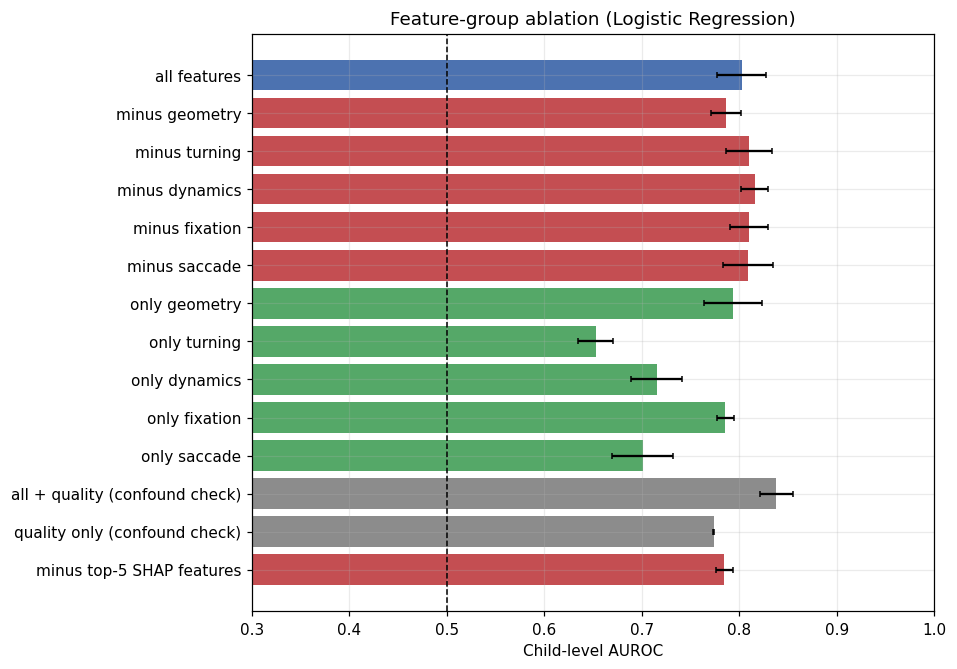

[time] ablation: 17.34 s


In [ ]:
# Cell 11. Ablation with the top-ranked model: drop one feature group, keep one group, add quality features
t=time.time(); abl=[]; best_nm=order[0]; print('Ablation model:',best_nm)
def run_cfg(label,cols_):
    r=cv_run(best_nm,cols_,data); ms=summarize_runs(r['child'])
    abl.append(dict(config=label,n_features=len(cols_),AUROC=ms.AUROC.mean(),AUROC_sd=ms.AUROC.std(),F1=ms.F1.mean(),Recall=ms.Recall.mean(),Precision=ms.Precision.mean(),MSE=ms.MSE.mean(),MAE=ms.MAE.mean()))
run_cfg('all features',FEATS)
for g,cs in GROUPS.items(): run_cfg(f'minus {g}',[c for c in FEATS if c not in cs])
for g,cs in GROUPS.items(): run_cfg(f'only {g}',cs)
run_cfg('all + quality (confound check)',FEATS+QUALITY)
run_cfg('quality only (confound check)',QUALITY)
if SHAPV: run_cfg('minus top-5 SHAP features',[c for c in FEATS if c not in imp_n.index[:5]])
A=pd.DataFrame(abl); A['dAUROC_vs_all']=A.AUROC-A.loc[0,'AUROC']; A.to_csv(OUT/'ablation.csv',index=False)
print(A.round(3).to_string(index=False))
fig,ax=plt.subplots(figsize=(8,0.38*len(A)+1.5)); cl=['#4c72b0' if c=='all features' else '#c44e52' if 'minus' in c else '#55a868' if 'only' in c and 'quality' not in c else '#8c8c8c' for c in A.config]
ax.barh(A.config[::-1],A.AUROC[::-1],xerr=A.AUROC_sd[::-1],color=cl[::-1],capsize=2); ax.axvline(.5,color='k',ls='--',lw=1); ax.set_xlim(.3,1.0)
ax.set_xlabel('Child-level AUROC'); ax.set_title(f'Feature-group ablation ({best_nm})'); save(fig,'11_ablation'); tick('ablation',t)

Real LR AUROC 0.802 | shuffled mean 0.473 (95th pct 0.602) | permutation p = 0.0323


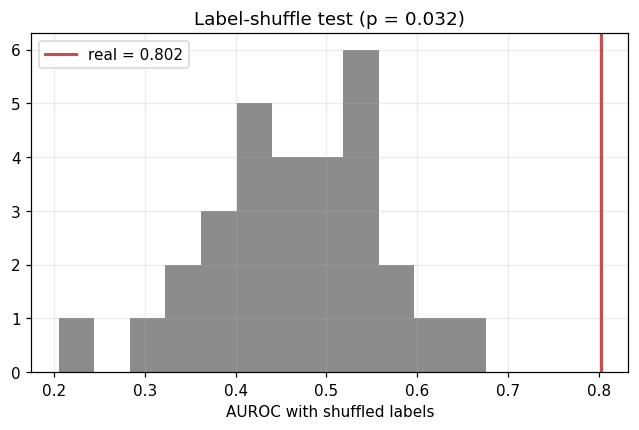

[time] permutation_test: 17.86 s


In [ ]:
# Cell 12. Label-shuffle check: AUROC when child labels are randomly reassigned (Logistic Regression, fast)
t=time.time(); rng=np.random.default_rng(SEED); kids=data.groupby('pid')['label'].first(); real=MS['Logistic Regression'].AUROC.mean(); perm=[]
for i in range(N_PERM):
    sh=pd.Series(rng.permutation(kids.values),index=kids.index); d2=data.copy(); d2['label_perm']=d2['pid'].map(sh)
    r=cv_run('Logistic Regression',FEATS,d2,repeats=1,label_col='label_perm'); perm.append(roc_auc_score(r['child'][0].y,r['child'][0].p))
perm=np.array(perm); pval=(1+(perm>=real).sum())/(1+len(perm))
print(f'Real LR AUROC {real:.3f} | shuffled mean {perm.mean():.3f} (95th pct {np.percentile(perm,95):.3f}) | permutation p = {pval:.4f}')
fig,ax=plt.subplots(figsize=(7,4)); ax.hist(perm,bins=12,color='#8c8c8c'); ax.axvline(real,color='#c44e52',lw=2,label=f'real = {real:.3f}'); ax.legend(); ax.set(xlabel='AUROC with shuffled labels',title=f'Label-shuffle test (p = {pval:.3f})'); save(fig,'12_permutation_test')
pd.DataFrame({'perm_auroc':perm}).to_csv(OUT/'permutation_auroc.csv',index=False); tick('permutation_test',t)

In [ ]:
# Cell 13. Computation report, summary, zip for download
import sklearn, scipy
try:
    import psutil; ram=round(psutil.virtual_memory().total/1e9,1)
except Exception: ram=None
try:
    import torch; gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'
except Exception: gpu='none (torch not installed; none of these models use a GPU)'
TIMES['total_notebook']=round(time.time()-T0,1)
comp=dict(python=platform.python_version(),platform=platform.platform(),cpu_count=os.cpu_count(),ram_gb=ram,gpu=gpu,
          numpy=np.__version__,pandas=pd.__version__,sklearn=sklearn.__version__,scipy=scipy.__version__,
          xgboost=__import__('xgboost').__version__ if HAS_XGB else None,shap=shap.__version__,
          cv=f'{N_REPEATS}x repeated {N_SPLITS}-fold StratifiedGroupKFold by child',n_model_fits=int(sum(RUNS[m]['n_fits'] for m in MODELS)),
          shared_only=bool(SHARED_ONLY),screen=[SCREEN_W,SCREEN_H],stage_seconds=TIMES)
summary=dict(n_trials=int(len(data)),n_children=int(data['pid'].nunique()),children_per_class=data.groupby('Class')['pid'].nunique().to_dict(),
    ranking=order,rank_weights=rank_w.round(4).to_dict(),child_level_metrics={k:{m:round(float(final.loc[k,m]),4) for m in show} for k in ALL},
    permutation=dict(real_auroc=float(real),shuffled_mean=float(perm.mean()),p=float(pval)),ablation=A.round(4).to_dict('records'),computation=comp,
    reference_resnet50_scanpath_image={'note':'7 test children, one split, not comparable','child_AUROC':0.917,'child_F1':0.750})
json.dump(summary,open(OUT/'summary.json','w'),indent=2,default=str)
print(pd.Series(TIMES).to_string()); print(json.dumps({k:comp[k] for k in comp if k!='stage_seconds'},indent=1,default=str))

top_stat=st[st.p_BH<.05]
print(f"\nFeatures significant at BH q<0.05 (child level): {len(top_stat)} of {len(st)}")
print('Best single model:',order[0],'| ensemble AUROC (rank-weighted):',round(final.loc['Ensemble (rank-weighted)','AUROC'],3))
print('Caution: ~%d children; rank weights were chosen from the same out-of-fold results, so ensemble figures are slightly optimistic.'%data['pid'].nunique())
qa=A[A.config.str.startswith('quality only')].AUROC.iloc[0]; fa=A.loc[0,'AUROC']
if qa>=fa-0.03: print(f'WARNING: tracking-quality features alone reach AUROC {qa:.3f} (full model {fa:.3f}). Blink rate and valid-sample ratio differ by group, so part of the signal may reflect recording quality, not gaze geometry. Velocity and acceleration features are the most exposed to tracker noise.')
dm=A[A.config=='minus dynamics'].dAUROC_vs_all.iloc[0]
if dm>0.02: print(f'NOTE: removing the dynamics group raised AUROC by {dm:.3f}; those features may add noise for this sample size.')
import shutil; shutil.make_archive('outputs','zip','outputs'); print('Wrote outputs.zip',round(os.path.getsize('outputs.zip')/1e6,2),'MB')
try:
    from google.colab import files; files.download('outputs.zip')
except Exception: pass

feature_extraction      27.26
statistics               2.33
train_3_models_cv       35.59
rank_and_ensemble        0.11
plots_models             3.72
shap                    37.80
ablation                17.34
permutation_test        17.86
total_notebook        1205.70
{
 "python": "3.13.15",
 "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
 "cpu_count": 2,
 "ram_gb": 13.6,
 "gpu": "Tesla T4",
 "numpy": "2.1.3",
 "pandas": "2.2.3",
 "sklearn": "1.6.1",
 "scipy": "1.16.3",
 "xgboost": "3.4.1",
 "shap": "0.52.0",
 "cv": "3x repeated 5-fold StratifiedGroupKFold by child",
 "n_model_fits": 45,
 "shared_only": false,
 "screen": [
  1280.0,
  1024.0
 ]
}

Features significant at BH q<0.05 (child level): 17 of 34
Best single model: Logistic Regression | ensemble AUROC (rank-weighted): 0.789
Caution: ~57 children; rank weights were chosen from the same out-of-fold results, so ensemble figures are slightly optimistic.
Wrote outputs.zip 2.23 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>